# ML A/B Testing: LogReg vs RandomForest vs LightGBM on Dry Bean

This notebook walks through the experiment step by step. The heavy lifting (300+ model fits) is done
by `scripts/run_experiment.py`. This notebook loads the cached results, so it executes in seconds.
If no cache exists, it runs the experiment first (about 10 minutes).

**Design (pre-registered, see `docs/PLAN.md`):**
- Primary metric: macro-F1
- α = 0.05 with Holm correction
- Minimum practically meaningful difference (MPD) = 0.01

**Tests:**
- Corrected resampled t-test (primary)
- 5×2cv t / F
- McNemar
- Paired bootstrap
- TOST equivalence

In [1]:
import sys, pickle, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from abtest import config
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 160)

cache = config.DATA_DIR / "results_cache.pkl"
if not cache.exists():
    from abtest.experiment import run, save
    from abtest.plots import make_all_figures
    res = run(); save(res); make_all_figures(res)
    pickle.dump(res, open(cache, "wb"))
res = pickle.load(open(cache, "rb"))
fig = lambda name: display(Image(filename=str(config.FIGURES_DIR / name), width=850))
print(json.dumps({k: v for k, v in res.meta.items() if k not in ("models", "versions")}, indent=1))

{
 "seed": 42,
 "n_raw_rows": 13611,
 "n_duplicates_dropped": 68,
 "n_dev": 10834,
 "n_holdout": 2709,
 "classes": [
  "BARBUNYA",
  "BOMBAY",
  "CALI",
  "DERMASON",
  "HOROZ",
  "SEKER",
  "SIRA"
 ],
 "cv": "10x10 repeated stratified K-fold",
 "mean_n_train": 9750.6,
 "mean_n_test": 1083.4,
 "primary_metric": "f1_macro",
 "alpha": 0.05,
 "mpd": 0.01,
 "n_bootstrap": 10000,
 "python": "3.13.18",
 "runtime_seconds": 459.1
}


## 1. Data
The raw table has 13,611 beans with 16 shape features. Exact duplicates are dropped, then the data is split 80/20 into stratified development and hold-out sets.

In [2]:
ds = res.dataset
print(f"raw rows={ds.n_raw:,}  duplicates dropped={ds.n_duplicates}  dev={len(ds.y_dev):,}  hold-out={len(ds.y_holdout):,}")
ds.X_dev.describe().T[["mean", "std", "min", "max"]]

raw rows=13,611  duplicates dropped=68  dev=10,834  hold-out=2,709


,mean,std,min,max
Area,53017.5202,29355.8649,20420.0000,248424.0000
Perimeter,854.6360,214.4839,524.7360,1895.9400
MajorAxisLength,319.7864,85.7217,183.6012,726.3735
MinorAxisLength,202.3239,45.0483,122.5127,460.1985
AspectRation,1.5809,0.2452,1.0249,2.4303
Eccentricity,0.7502,0.0919,0.2190,0.9114
ConvexArea,53736.1198,29803.0519,20684.0000,251082.0000
EquivDiameter,252.9643,59.2740,161.2438,562.4084
Extent,0.7499,0.0487,0.5553,0.8662
Solidity,0.9872,0.0047,0.9192,0.9947


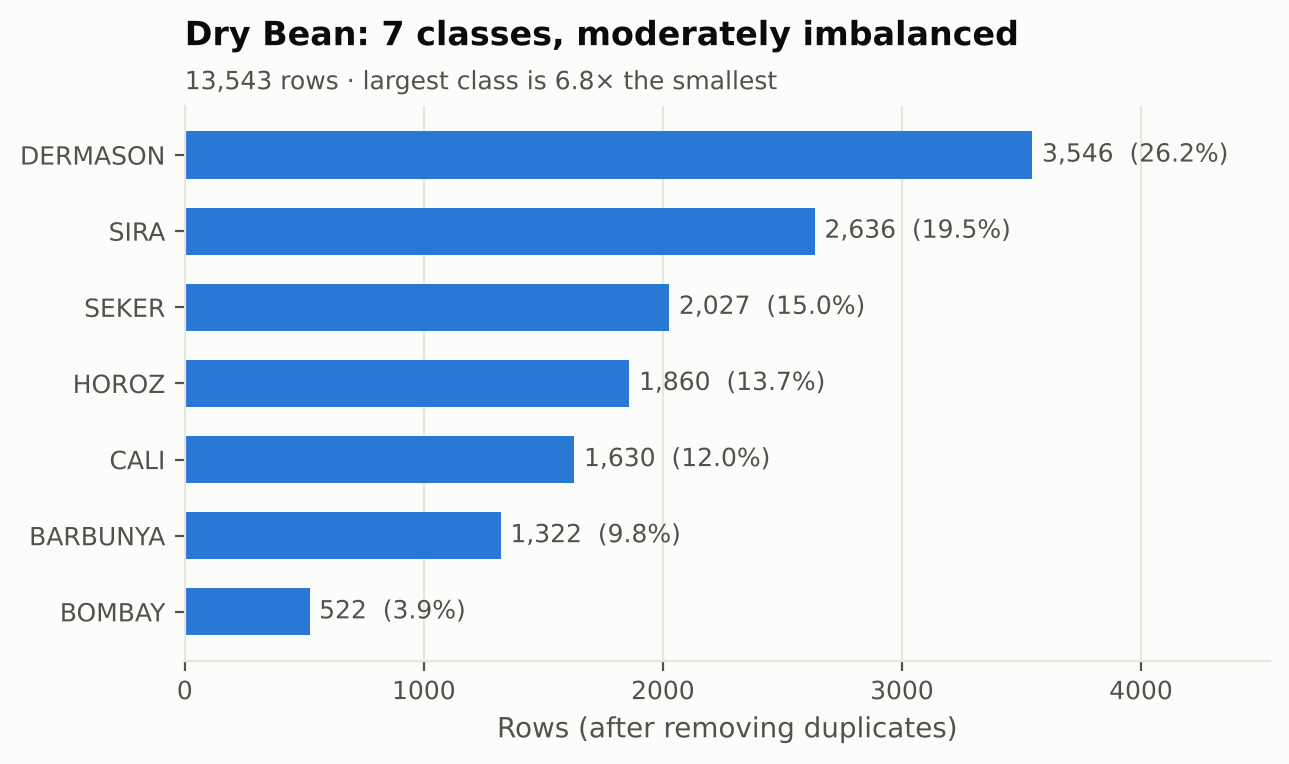

In [3]:
fig("01_class_distribution.png")

## 2. Cross-validated performance (10×10 repeated stratified CV)
The table shows the mean ± sd of each metric over 100 test folds. Every model saw **identical folds**, so the scores are paired.

In [4]:
summary = res.cv.groupby("model")[["f1_macro","accuracy","precision_macro","recall_macro","f1_weighted","hamming_loss","mcc","cohen_kappa","log_loss","fit_seconds"]].agg(["mean","std"]).loc[config.MODEL_ORDER]
summary

f1_macro        accuracy        precision_macro        recall_macro        f1_weighted        hamming_loss           mcc        cohen_kappa  \
                 mean    std     mean    std            mean    std         mean    std        mean    std         mean    std   mean    std        mean   
model                                                                                                                                                      
LogReg         0.9368 0.0066   0.9247 0.0072          0.9383 0.0065       0.9359 0.0067      0.9248 0.0072       0.0753 0.0072 0.9090 0.0087      0.9089   
RandomForest   0.9369 0.0067   0.9257 0.0075          0.9388 0.0068       0.9355 0.0069      0.9256 0.0075       0.0743 0.0075 0.9102 0.0091      0.9101   
LightGBM       0.9411 0.0071   0.9288 0.0080          0.9433 0.0069       0.9393 0.0074      0.9288 0.0079       0.0712 0.0080 0.9139 0.0096      0.9138   

                    log_loss        fit_seconds         
                std     mean    std        mean    std  
model                                                   
LogReg       0.0087   0.2141 0.0210      0.1515 0.0227  
RandomForest 0.0091   0.2753 0.0541     11.0901 0.4238  
LightGBM     0.0096   0.3398 0.0492      3.6806 0.1919

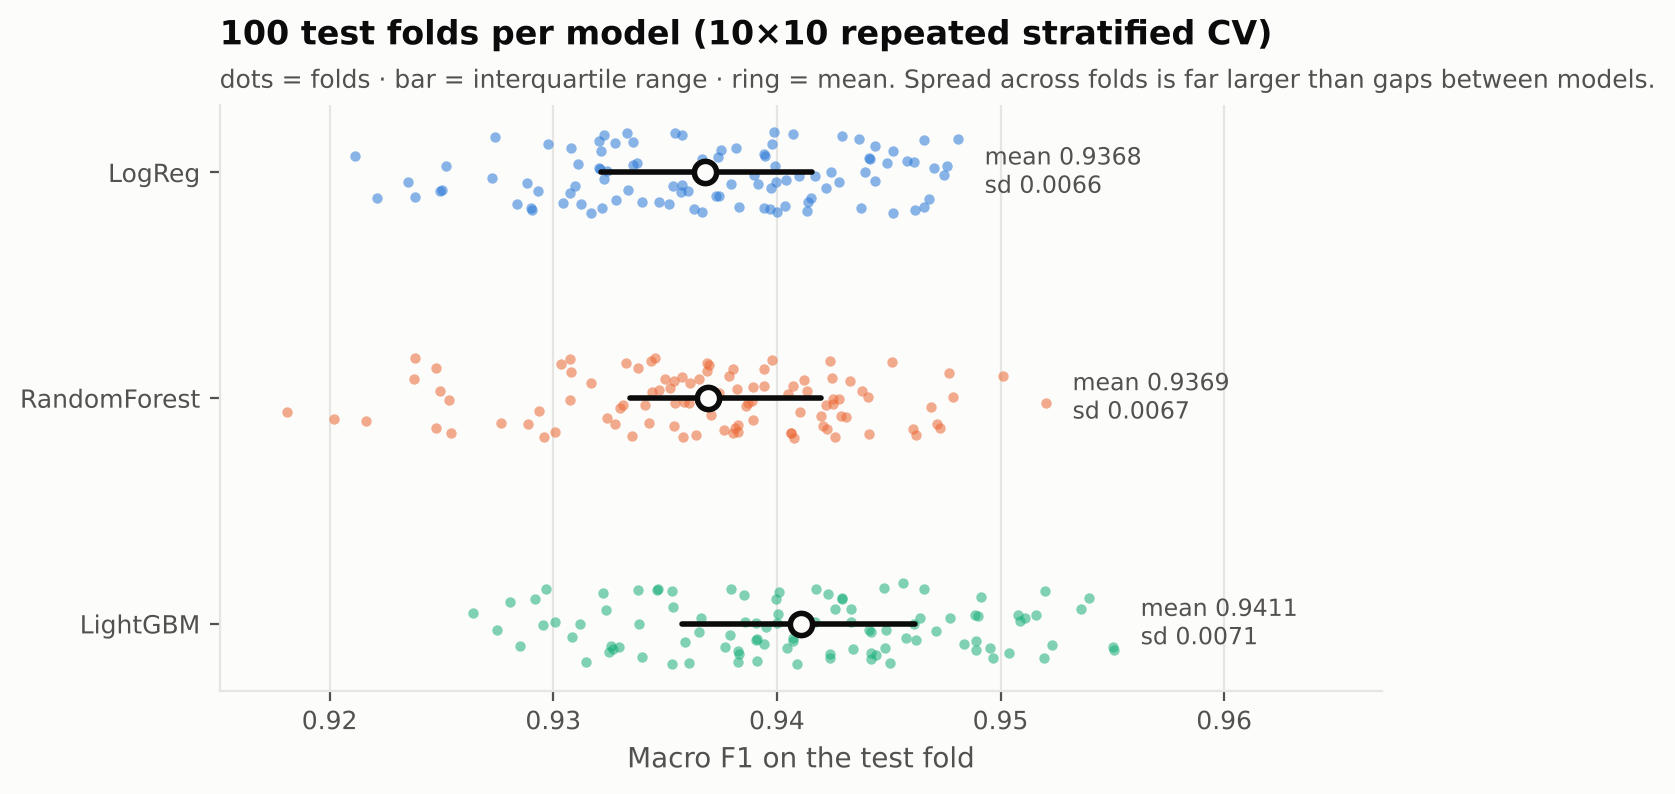

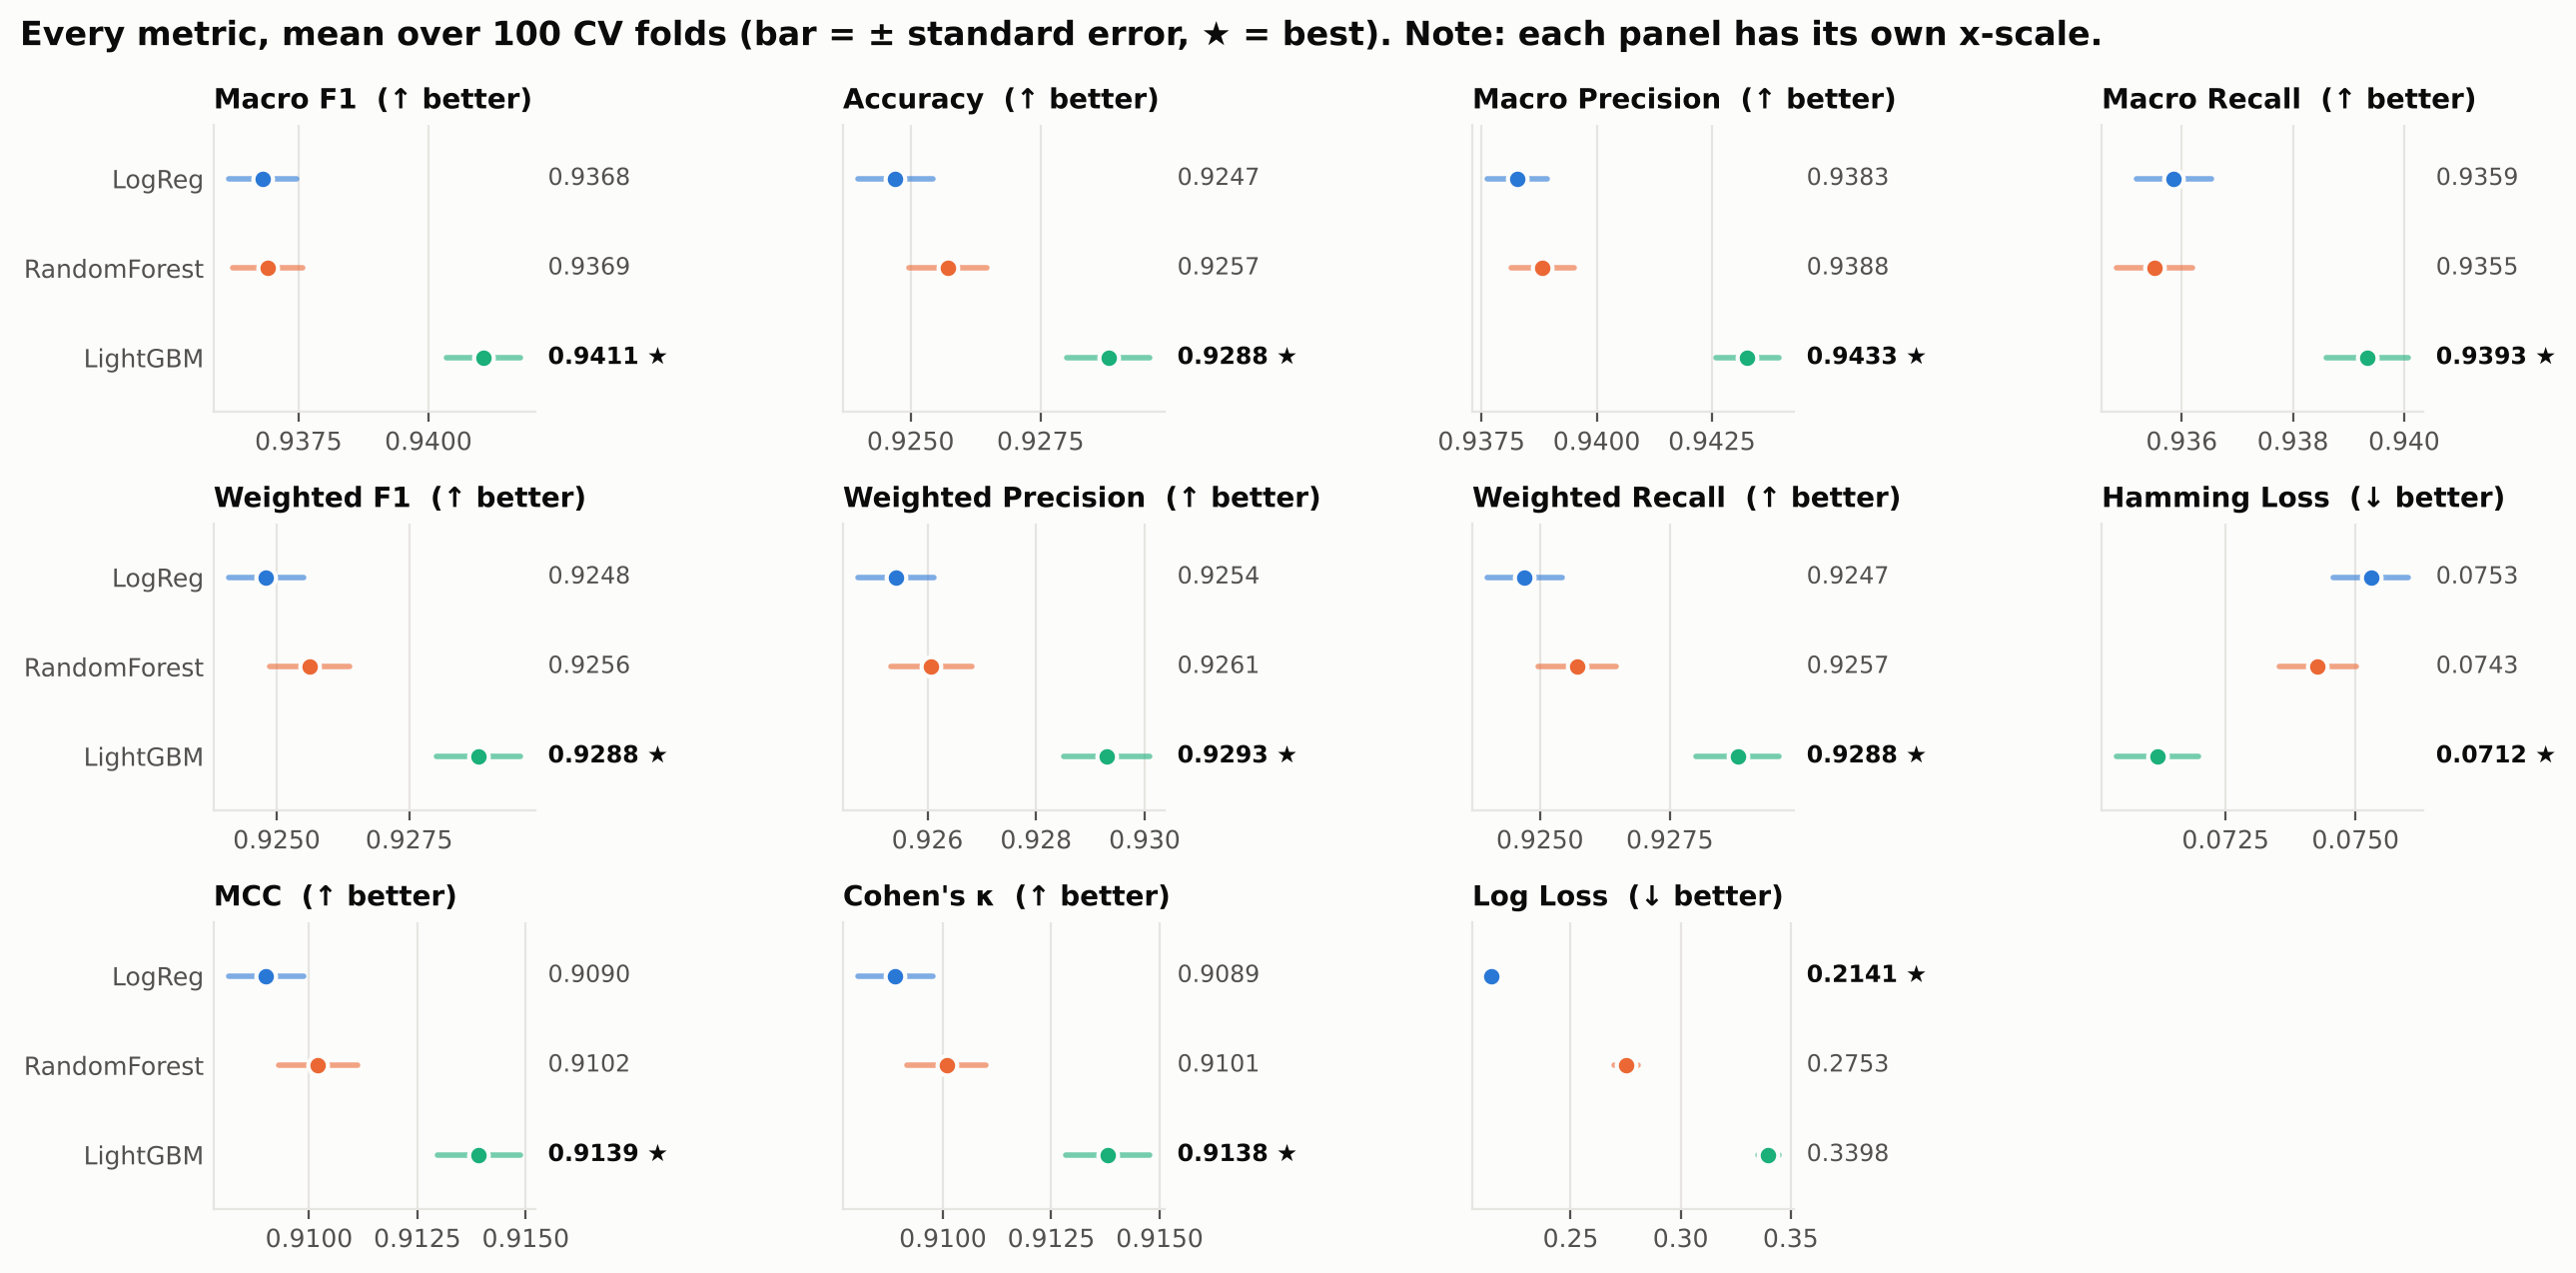

In [5]:
fig("02_cv_macro_f1_by_model.png")
fig("06_all_metrics_cv_mean.png")

**Hamming Loss check.** For single-label multi-class problems, Hamming Loss equals 1 − accuracy, as the next cell confirms:

In [6]:
np.abs(res.cv["hamming_loss"] - (1 - res.cv["accuracy"])).max()

np.float64(5.551115123125783e-17)

## 3. Primary test: corrected resampled t-test on macro-F1
The naive t-test is shown next to it to illustrate how badly it understates the uncertainty.

In [7]:
cols = ["comparison","mean_diff","ci_low","ci_high","cohens_dz","wins_1","wins_2",
        "p_naive","p_corrected","p_holm_naive","p_holm_corrected"]
res.cv_tests[cols]

,comparison,mean_diff,ci_low,ci_high,cohens_dz,wins_1,wins_2,p_naive,p_corrected,p_holm_naive,p_holm_corrected
0,RandomForest vs LogReg,0.0001,-0.0032,0.0034,0.0211,46,54,0.8334,0.9518,0.8334,0.9518
1,LightGBM vs LogReg,0.0043,0.0005,0.0080,0.7799,81,19,0.0000,0.0273,0.0000,0.0545
2,LightGBM vs RandomForest,0.0042,0.0008,0.0075,0.8583,79,21,0.0000,0.0154,0.0000,0.0461


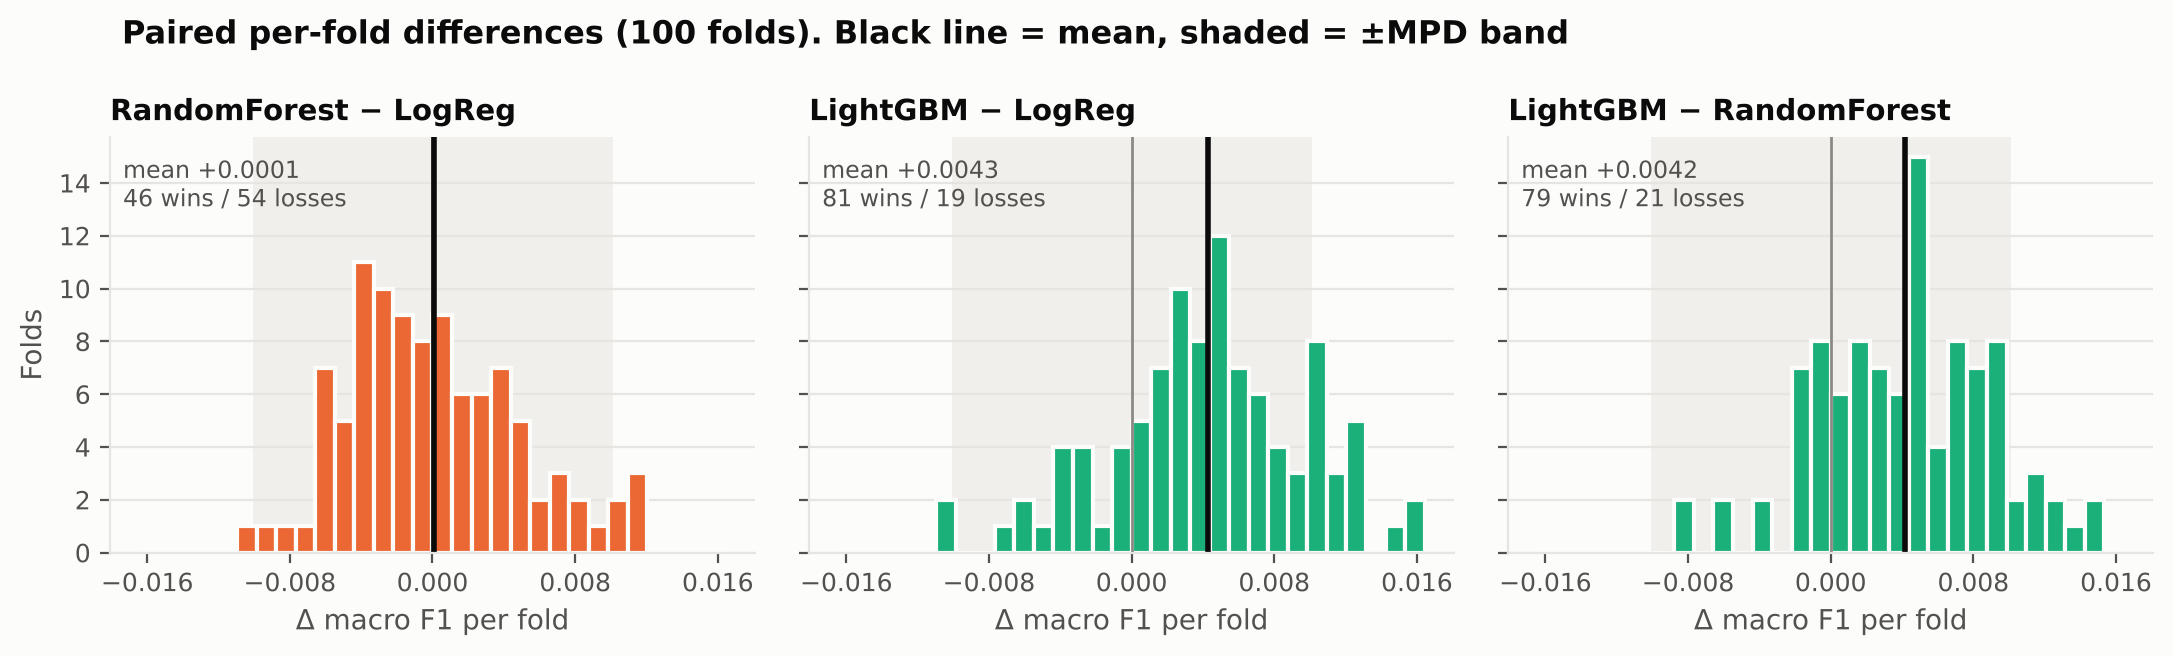

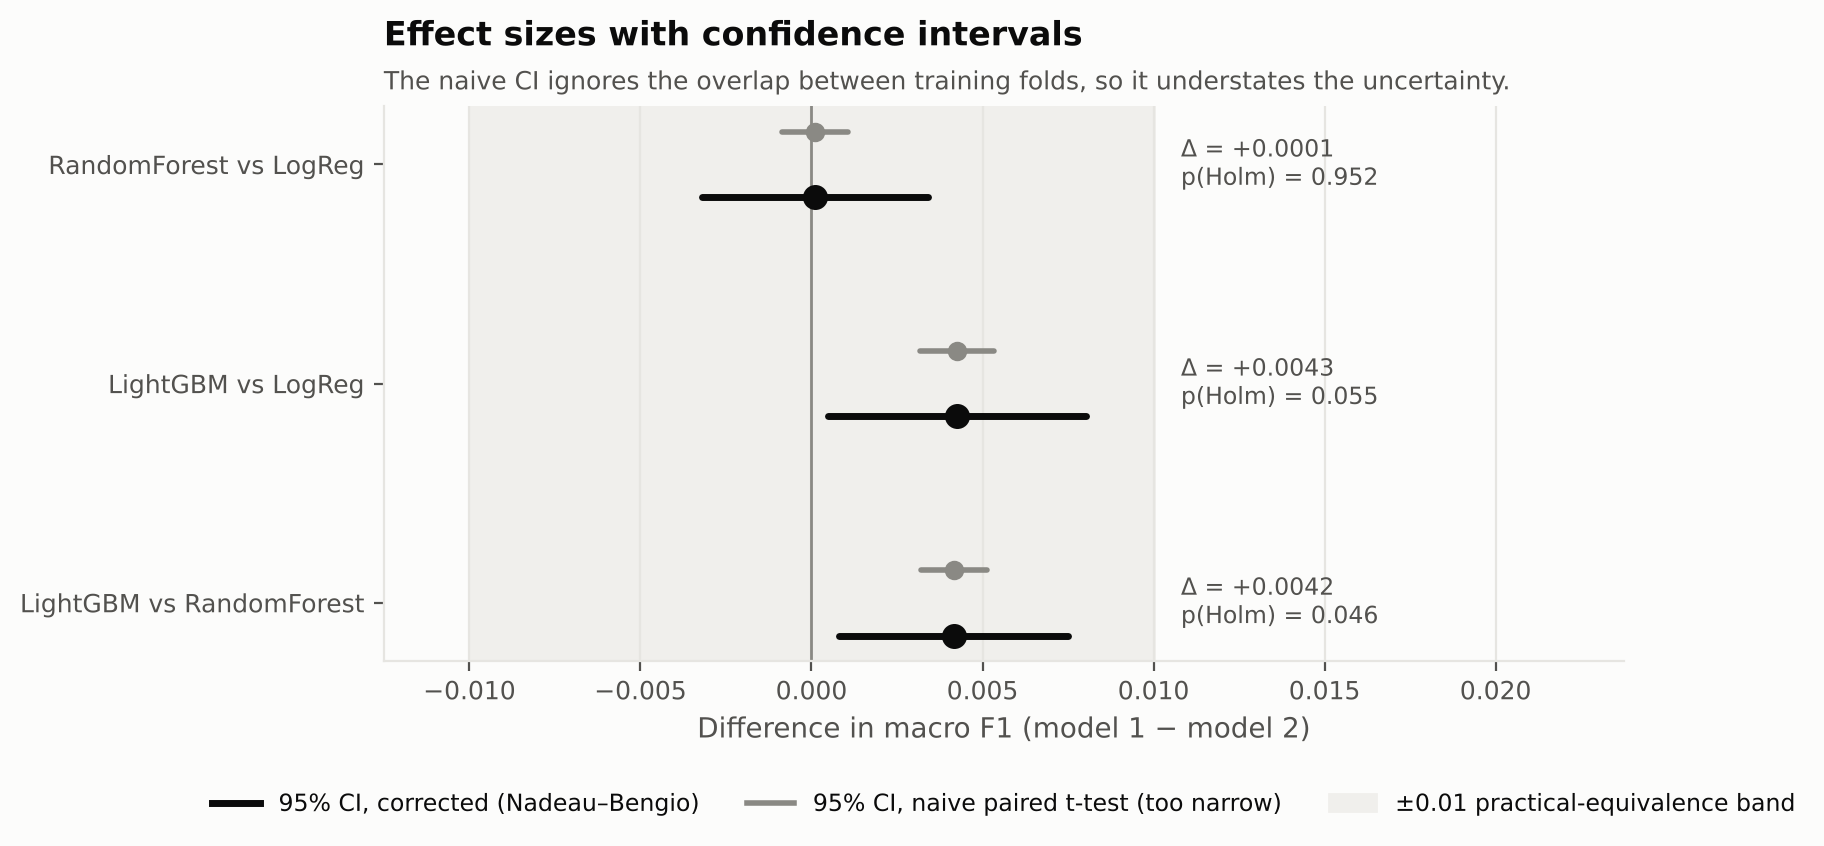

In [8]:
fig("05_paired_fold_differences.png")
fig("03_forest_plot_differences.png")

## 4. Second opinion: 5×2cv paired t-test and combined F-test

In [9]:
res.cv_tests[["comparison","t_5x2","p_5x2","p_holm_5x2","f_5x2_combined","p_5x2_combined_f","p_holm_5x2_combined_f"]]

,comparison,t_5x2,p_5x2,p_holm_5x2,f_5x2_combined,p_5x2_combined_f,p_holm_5x2_combined_f
0,RandomForest vs LogReg,-0.6360,0.5527,0.5527,4.1700,0.0642,0.1285
1,LightGBM vs LogReg,1.8582,0.1223,0.2445,1.5197,0.3368,0.3368
2,LightGBM vs RandomForest,7.6400,0.0006,0.0018,57.7071,0.0002,0.0005


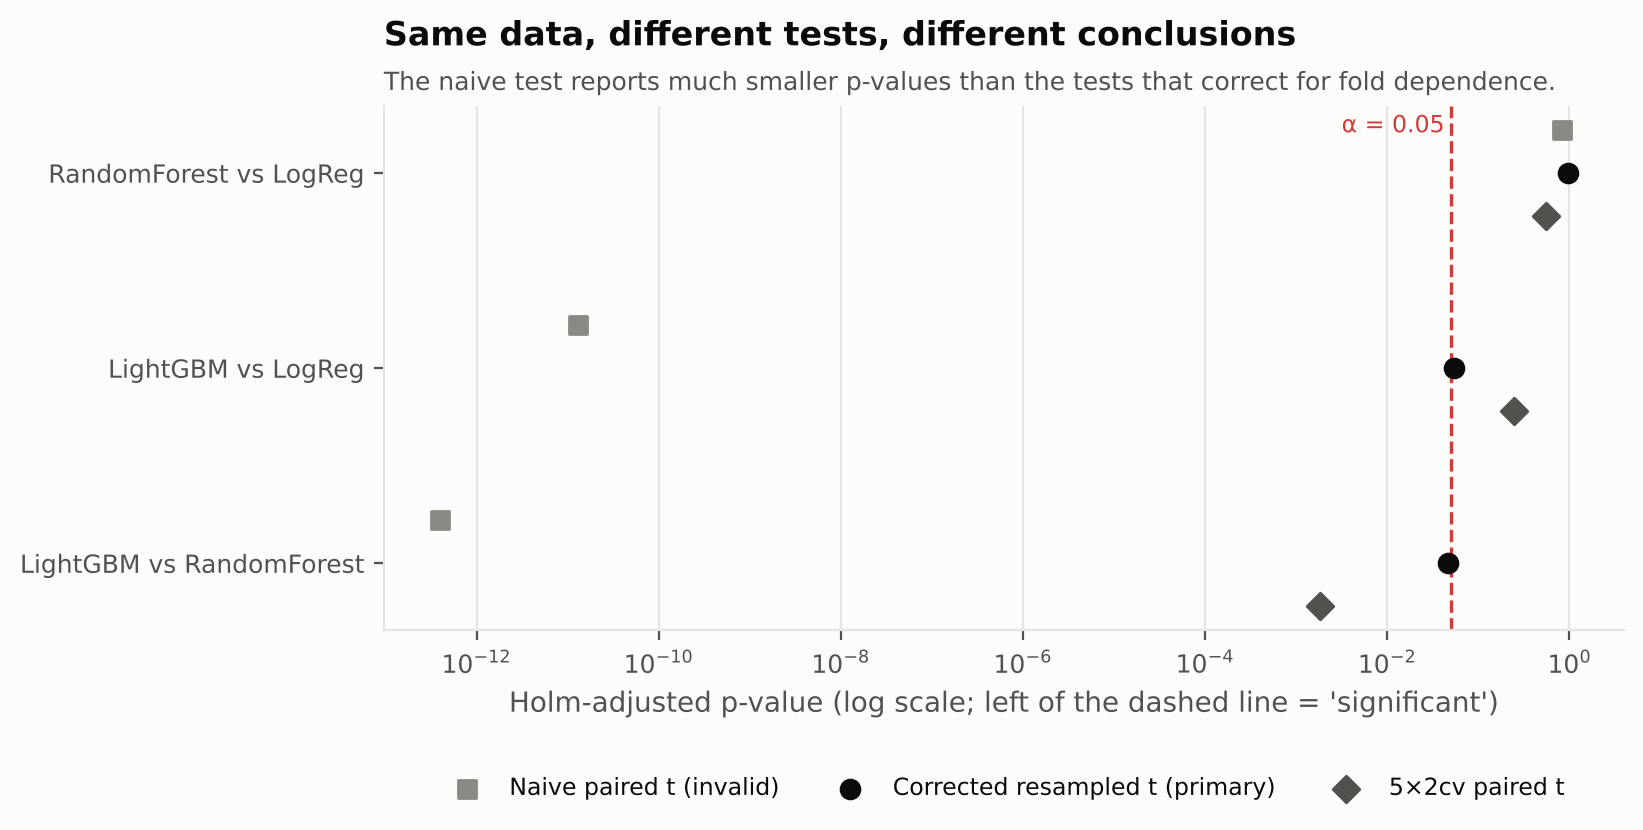

In [10]:
fig("04_pvalues_by_test.png")

## 5. Equivalence: TOST with ±0.01 margin
Equivalence is declared when the 90% CI lies entirely inside ±0.01.

In [11]:
res.cv_tests[["comparison","mean_diff","tost_ci90_low","tost_ci90_high","tost_p","tost_equivalent"]]

,comparison,mean_diff,tost_ci90_low,tost_ci90_high,tost_p,tost_equivalent
0,RandomForest vs LogReg,0.0001,-0.0027,0.0029,0.0000,True
1,LightGBM vs LogReg,0.0043,0.0011,0.0074,0.0016,True
2,LightGBM vs RandomForest,0.0042,0.0014,0.0070,0.0004,True


## 6. Hold-out set: metrics, McNemar and paired bootstrap
Each model is fitted once on the full development set and scored once on the untouched hold-out set.

In [12]:
res.holdout_metrics

,f1_macro,accuracy,precision_macro,recall_macro,f1_weighted,precision_weighted,recall_weighted,hamming_loss,mcc,cohen_kappa,log_loss
model,,,,,,,,,,,
LogReg,0.9302,0.9192,0.9307,0.9300,0.9193,0.9197,0.9192,0.0808,0.9023,0.9023,0.2183
RandomForest,0.9302,0.9188,0.9313,0.9293,0.9187,0.9188,0.9188,0.0812,0.9018,0.9017,0.2757
LightGBM,0.9286,0.9155,0.9298,0.9275,0.9156,0.9158,0.9155,0.0845,0.8977,0.8977,0.3814


In [13]:
res.holdout_tests

,comparison,model_1,model_2,both_correct,only_1_correct,only_2_correct,both_wrong,p_mcnemar,macro_f1_diff,boot_ci_low,boot_ci_high,p_bootstrap,p_holm_mcnemar,p_holm_bootstrap
0,RandomForest vs LogReg,RandomForest,LogReg,2439,50,51,169,1.0000,-0.0000,-0.0065,0.0065,0.9908,1.0000,1.0000
1,LightGBM vs LogReg,LightGBM,LogReg,2426,54,64,165,0.4075,-0.0017,-0.0084,0.0052,0.6330,0.8418,1.0000
2,LightGBM vs RandomForest,LightGBM,RandomForest,2457,23,32,197,0.2806,-0.0016,-0.0063,0.0030,0.4864,0.8418,1.0000


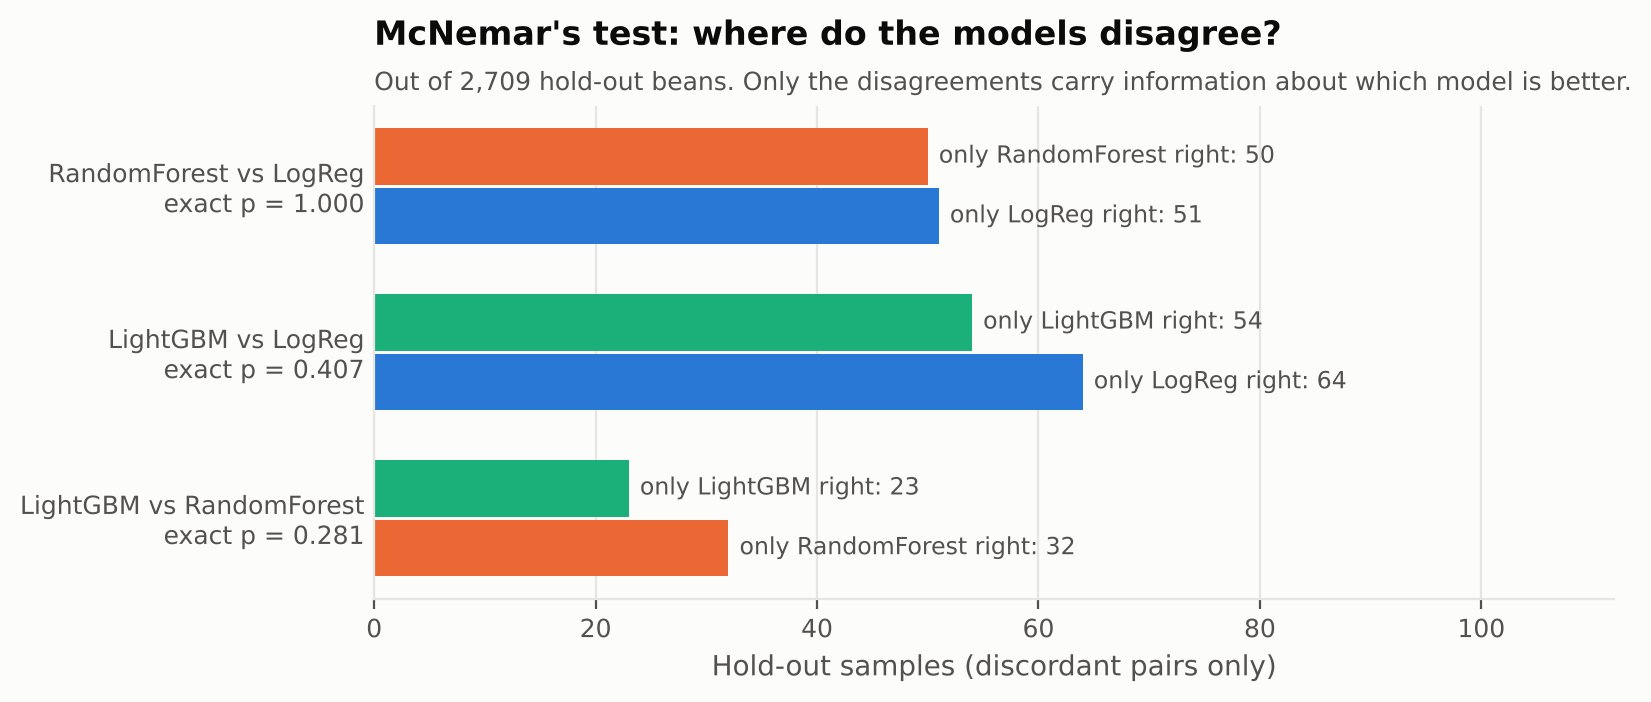

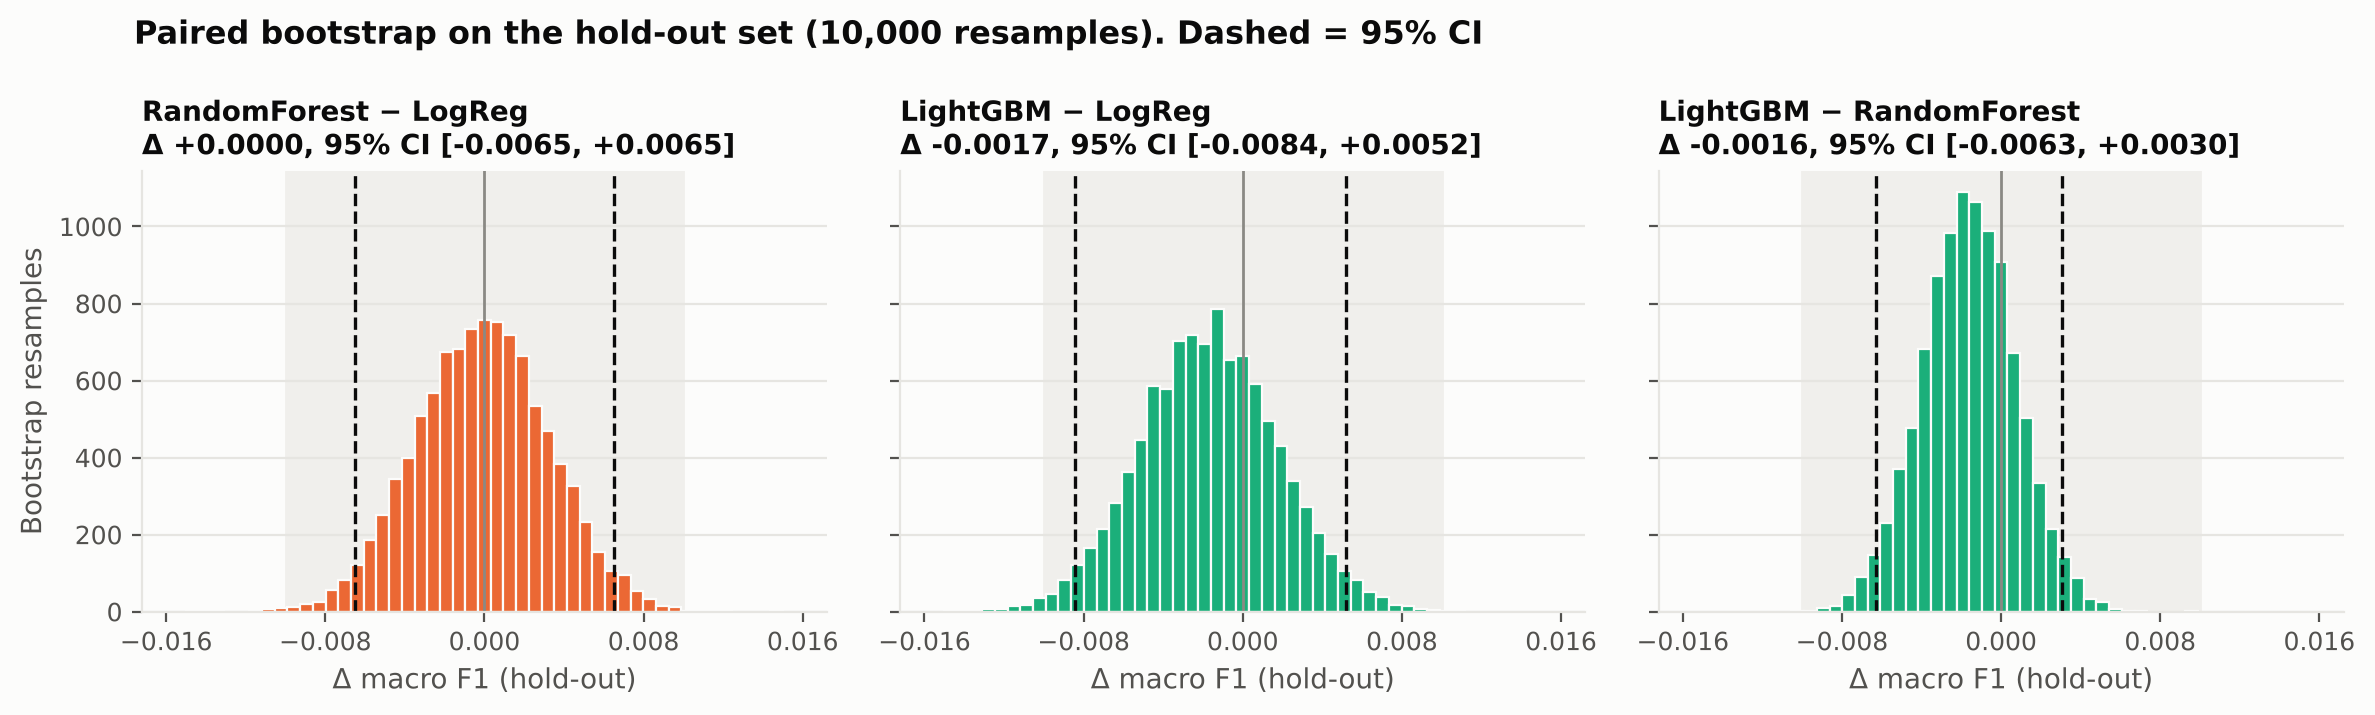

In [14]:
fig("10_mcnemar_discordant_pairs.png")
fig("09_bootstrap_holdout.png")

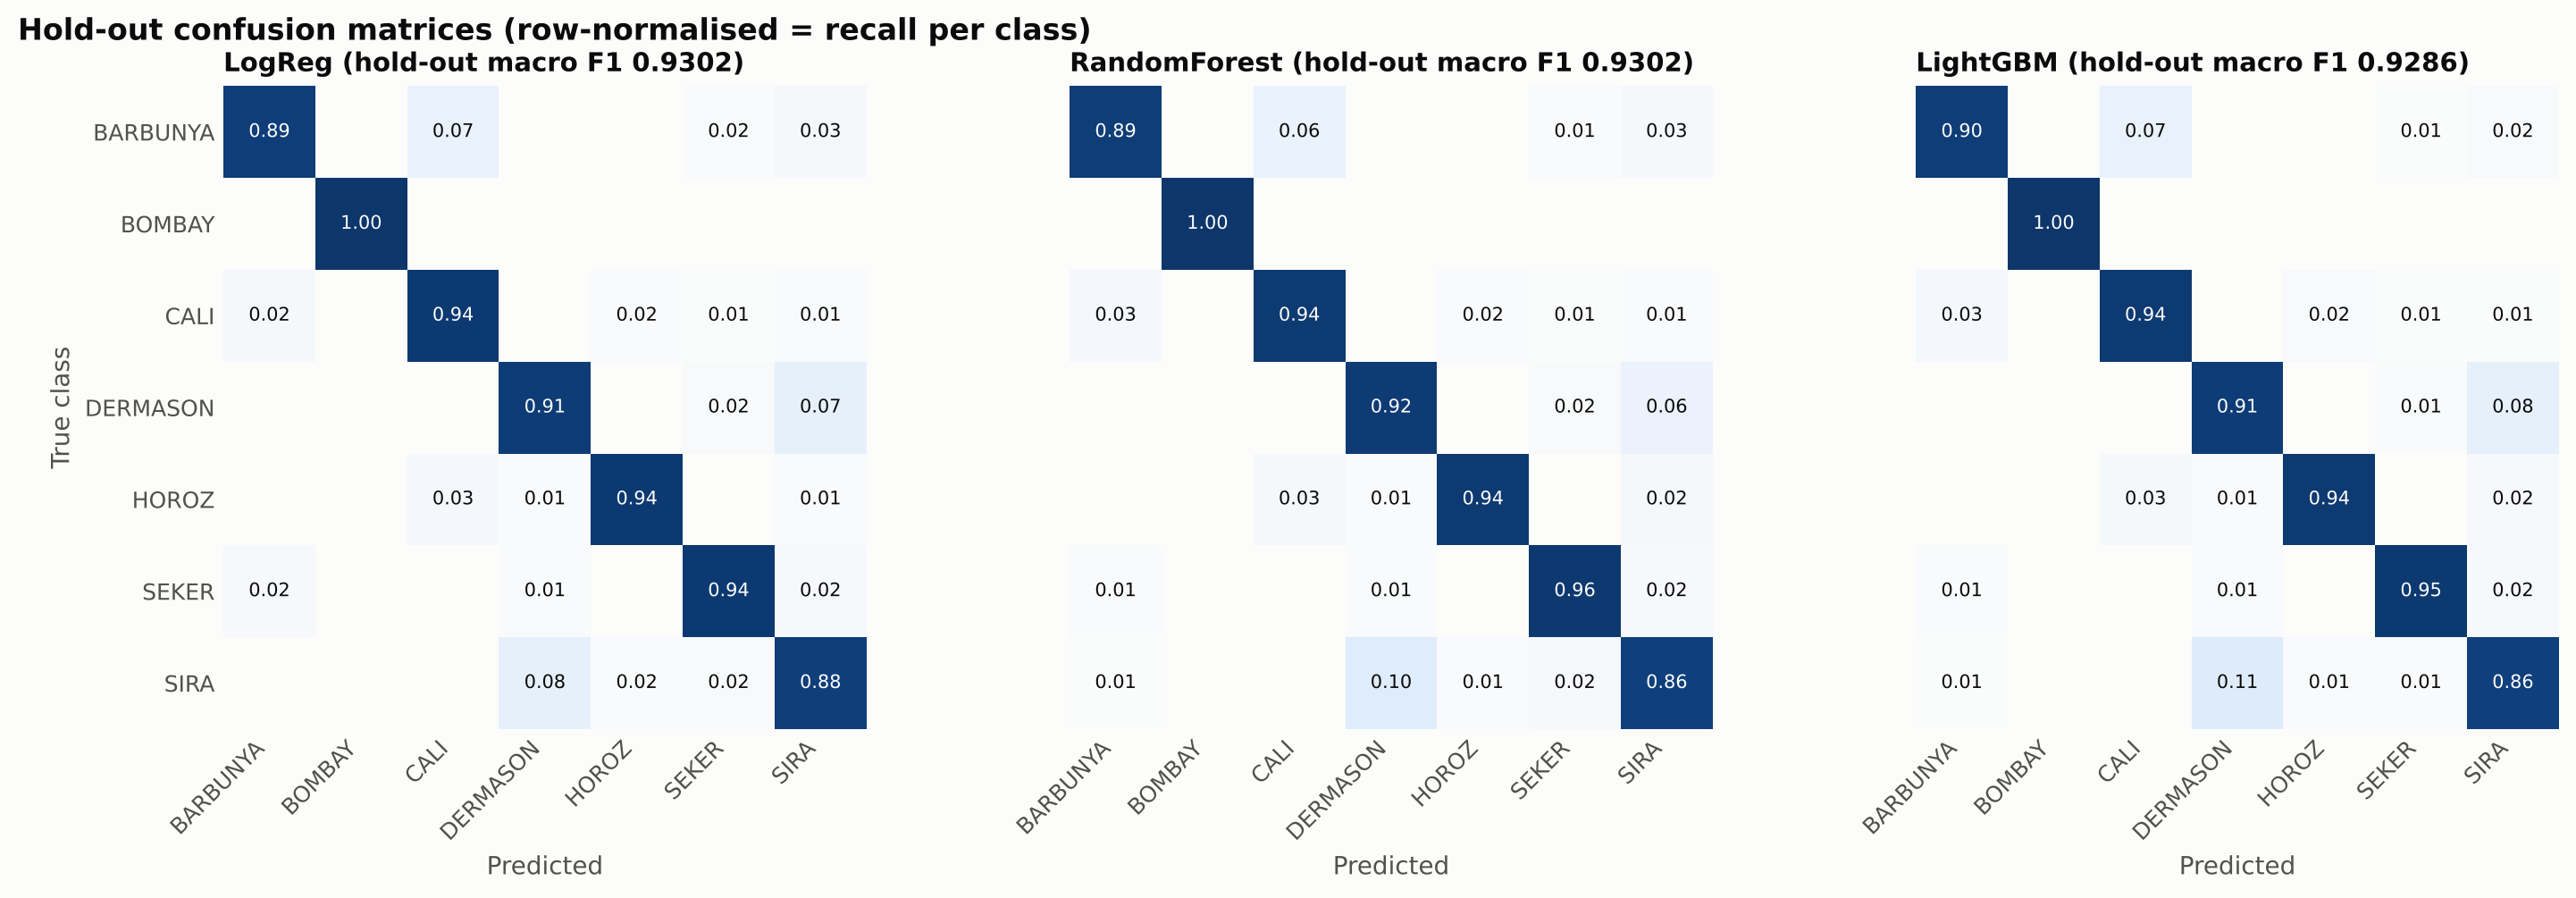

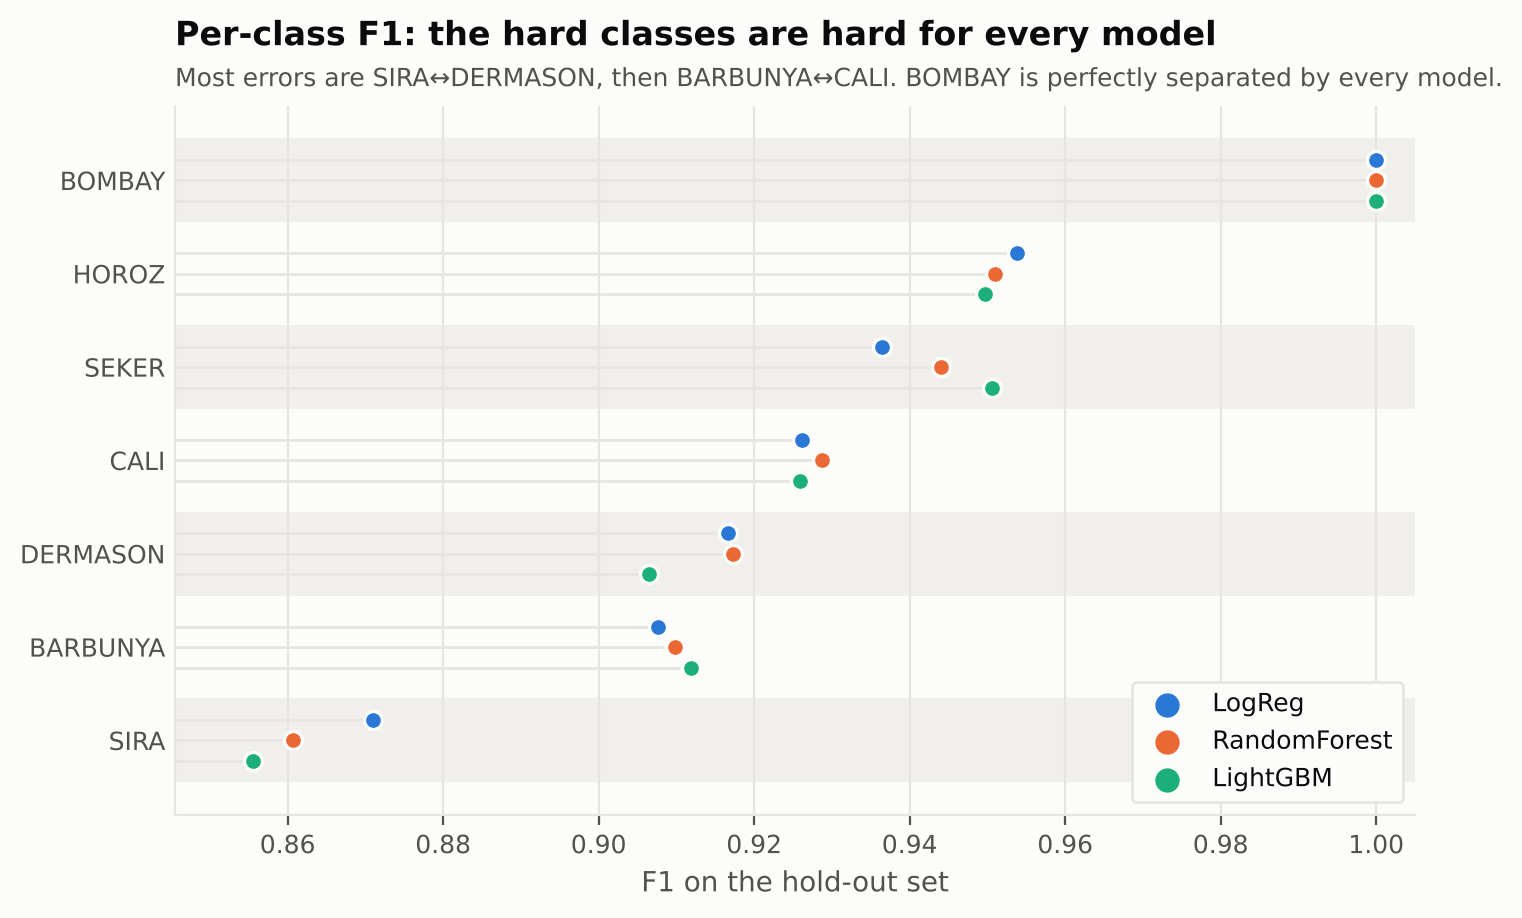

In [15]:
fig("07_confusion_matrices_holdout.png")
fig("08_per_class_f1_holdout.png")

## 7. Secondary metrics (exploratory)
The corrected t-test is applied to every metric, with Holm correction within each metric. These results are exploratory: the decision rests on the primary metric only.

In [16]:
sec = res.secondary_tests.pivot_table(index="metric_label", columns="comparison", values="mean_diff")
sig = res.secondary_tests.pivot_table(index="metric_label", columns="comparison", values="p_holm_within_metric")
print("Mean difference (model 1 − model 2):"); display(sec)
print("Holm-adjusted p (corrected t):"); display(sig)

Mean difference (model 1 − model 2):


comparison,LightGBM vs LogReg,LightGBM vs RandomForest,RandomForest vs LogReg
metric_label,,,
Accuracy,0.0041,0.0031,0.0010
Cohen's κ,0.0049,0.0037,0.0012
Hamming Loss,-0.0041,-0.0031,-0.0010
Log Loss,0.1258,0.0645,0.0612
MCC,0.0049,0.0037,0.0012
Macro F1,0.0043,0.0042,0.0001
Macro Precision,0.0050,0.0044,0.0006
Macro Recall,0.0035,0.0038,-0.0003
Weighted F1,0.0040,0.0032,0.0008


Holm-adjusted p (corrected t):


comparison,LightGBM vs LogReg,LightGBM vs RandomForest,RandomForest vs LogReg
metric_label,,,
Accuracy,0.1806,0.1818,0.5960
Cohen's κ,0.1905,0.1905,0.6124
Hamming Loss,0.1806,0.1818,0.5960
Log Loss,0.0000,0.0001,0.0004
MCC,0.1867,0.1867,0.6064
Macro F1,0.0545,0.0461,0.9518
Macro Precision,0.0330,0.0330,0.7478
Macro Recall,0.1461,0.0698,0.8412
Weighted F1,0.1997,0.1997,0.6697


## 8. Decision

In [17]:
res.decisions

,comparison,mean_diff,ci_low,ci_high,p_holm_corrected,tost_equivalent,decision
0,RandomForest vs LogReg,0.0001,-0.0032,0.0034,0.9518,True,Not significant and TOST-equivalent → practica...
1,LightGBM vs LogReg,0.0043,0.0005,0.0080,0.0545,True,Not significant and TOST-equivalent → practica...
2,LightGBM vs RandomForest,0.0042,0.0008,0.0075,0.0461,True,"LightGBM is significantly better, but by < MPD..."


See the README for the written interpretation, limitations and the final recommendation.